# Label-based Drift Detection on Elec2

**Task:** (1) đọc Elec2 từ River và đánh giá prequential, (2) no-change baseline, (3) ADWIN/DDM trên luồng lỗi, (4) so sánh frozen model với retrain-on-drift. Biểu đồ accuracy theo thời gian và đánh dấu drift.

## 0. Cài đặt và tái lập

Chạy trên Python 3.11. River `Elec2()` có thể tải dữ liệu qua mạng ở lần đầu; cần internet hoặc dữ liệu đã được cache. Với môi trường mới, chạy lệnh sau **trong terminal cùng virtualenv**:

In [29]:
import platform
from collections import deque
from dataclasses import dataclass

import matplotlib.pyplot as plt
import pandas as pd
import river
from river import datasets, drift, naive_bayes

print("Python:", platform.python_version())
print("River:", river.__version__)

WARMUP = 2_000  # các mẫu dùng để huấn luyện ban đầu; không tính vào so sánh
RETRAIN_WINDOW = 2_000  # chỉ dùng nhãn đã quan sát trước thời điểm drift
ACCURACY_WINDOW = 500  # rolling accuracy để nhìn phản ứng theo thời gian
ADWIN_DELTA = 0.002
DDM_MIN_INSTANCES = 30


def make_model():
    # Gaussian Naive Bayes: mô hình tăng dần, không yêu cầu chuẩn hoá feature.
    return naive_bayes.GaussianNB()


def make_detector(kind):
    if kind == "ADWIN":
        return drift.ADWIN(delta=ADWIN_DELTA)
    if kind == "DDM":
        return drift.binary.DDM(warm_start=DDM_MIN_INSTANCES)
    raise ValueError(f"Detector không được hỗ trợ: {kind}")

Python: 3.11.11
River: 0.22.0


## 1. Dataset Elec2

Elec2 là bài toán phân loại nhị phân biến động giá điện ở New South Wales, Australia. Dữ liệu theo dòng thời gian, gồm **45.312 mẫu**, **8 thuộc tính** và nhãn `True`/`False` đại diện cho **UP/DOWN**. Những giá trị đầu vào như giá điện, nhu cầu và dòng trao đổi là *đặc trưng*; nhãn chỉ được dùng **sau** khi đưa ra dự đoán.

Không dùng `train_test_split(shuffle=True)` trong bài toán này.

In [30]:
dataset = datasets.Elec2()
print(dataset)
stream = iter(dataset)
first_x, first_y = next(stream)
print("Sample features:", first_x)
print("Sample label:", first_y)
assert len(first_x) == 8
assert isinstance(first_y, bool)
# Các vòng đánh giá bên dưới luôn tạo iterator Elec2() mới từ đầu.

Electricity prices in New South Wales.

This is a binary classification task, where the goal is to predict if the price of electricity
will go up or down.

This data was collected from the Australian New South Wales Electricity Market. In this market,
prices are not fixed and are affected by demand and supply of the market. They are set every
five minutes. Electricity transfers to/from the neighboring state of Victoria were done to
alleviate fluctuations.

      Name  Elec2                                                      
      Task  Binary classification                                      
   Samples  45,312                                                     
  Features  8                                                          
    Sparse  False                                                      
      Path  /home/trggonos/river_data/Elec2/electricity.csv            
       URL  https://maxhalford.github.io/files/datasets/electricity.zip
      Size  2.95 MiB               

## 2. No-change baseline — dự đoán nhãn trước đó

Với mẫu thứ `t`, dự đoán `ŷₜ = yₜ₋₁`. Nhãn của mẫu hiện tại chỉ dùng để tính accuracy, **sau đó** mới lưu làm nhãn trước cho lượt tiếp theo. Bỏ qua mẫu đầu vì không có nhãn trước để dự đoán.

Baseline này khác với mô hình cố định (frozen model) ở phần 4: nó có cập nhật bộ nhớ **một nhãn gần nhất** dù không huấn luyện mô hình ML.

In [31]:
previous_label = None
baseline_correct = 0
baseline_total = 0
baseline_history = []

for i, (x, y) in enumerate(datasets.Elec2(), start=1):
    if previous_label is not None:
        correct = int(previous_label == y)
        baseline_correct += correct
        baseline_total += 1
        baseline_history.append({"index": i, "correct": correct})
    previous_label = y

baseline_acc = baseline_correct / baseline_total
print(f"No-change accuracy = {baseline_acc:.4%} ({baseline_correct}/{baseline_total})")
assert baseline_total == i - 1

No-change accuracy = 85.3303% (38664/45311)


## 3. Prequential evaluation và ADWIN/DDM trên luồng lỗi

Đầu tiên xây một mô hình **online-learning reference** để có luồng lỗi theo giao thức test-then-train:

1. Gọi `predict_one(x)` trước khi thấy nhãn.
2. Tạo lỗi nhị phân `error = int(y_pred != y)`.
3. Đưa **chính cùng lỗi** vào ADWIN và DDM để so sánh công bằng vị trí cảnh báo.
4. Sau khi detector nhận lỗi, mới gọi `learn_one(x, y)`.

Mô hình ở bước này học sau mỗi mẫu; nó chỉ dùng để khảo sát detectors, **không phải** mô hình frozen dùng trong so sánh ở phần 4. Bỏ qua dự đoán `None` (mô hình chưa sẵn sàng).

In [32]:
reference_model = make_model()
monitor_adwin = make_detector("ADWIN")
monitor_ddm = make_detector("DDM")
reference_log = []
monitor_events = []

for i, (x, y) in enumerate(datasets.Elec2(), start=1):
    pred = reference_model.predict_one(x)  # TEST
    if pred is not None:
        err = int(pred != y)
        for name, det in [("ADWIN", monitor_adwin), ("DDM", monitor_ddm)]:
            det.update(err)
            if det.drift_detected:
                monitor_events.append({"index": i, "detector": name, "error": err})
        reference_log.append({"index": i, "correct": 1 - err})
    reference_model.learn_one(x, y)  # TRAIN: chỉ sau khi TEST

reference_df = pd.DataFrame(reference_log)
monitor_events_df = pd.DataFrame(monitor_events, columns=["index", "detector", "error"])
print("Reference prequential accuracy:", f"{reference_df['correct'].mean():.4%}")
print("Reference error-stream drift counts:")
print(
    monitor_events_df["detector"].value_counts().reindex(["ADWIN", "DDM"], fill_value=0).to_string()
)
display(monitor_events_df.head(30))

Reference prequential accuracy: 72.8741%
Reference error-stream drift counts:
detector
ADWIN     74
DDM      138


,index,detector,error
0,185,DDM,1
1,225,ADWIN,0
2,415,DDM,1
3,454,DDM,1
4,599,DDM,1
5,1278,DDM,1
6,1557,DDM,1
7,1658,DDM,1
8,1797,DDM,1
9,2136,DDM,1


## 4. Thí nghiệm chính — no update vs retrain on drift

**Thiết lập công bằng:**

- Cả ba mô hình đều học từ **cùng 2.000 mẫu đầu (warm-up)**, theo thứ tự thời gian.
- Sau warm-up, **Frozen** không được `learn_one` nữa.
- **Retrain + ADWIN** và **Retrain + DDM** đều được đánh giá dự đoán trước khi nhìn thấy nhãn. Mỗi mô hình có detector lỗi riêng.
- Khi một detector báo drift, tạo một mô hình mới và huấn luyện lại trên **tối đa 2.000 mẫu lịch sử đã xuất hiện trước mẫu hiện tại**, rồi reset detector. **Không** đưa nhãn hiện tại vào mô hình mới trước bước dự đoán của mẫu hiện tại.
- Dữ liệu lịch sử vẫn cập nhật sau khi nhãn được quan sát, nhưng mô hình chỉ update tại drift event. Không có incremental learning liên tục trên tập đánh giá.
- Drift points của hai nhánh retrain có thể khác với các điểm ở phần 3 vì mô hình và luồng lỗi khác nhau.

Đây là thiết kế *retrain from scratch on a recent labeled window*, không phải `partial_fit` liên tục. Không có trigger nếu model không suy giảm đủ để detector phát hiện.

In [33]:
@dataclass
class Branch:
    name: str
    model: object
    detector: object = None
    n_updates: int = 0


def evaluate_strategies():
    frozen = Branch("No update", make_model())
    branches = {
        "No update": frozen,
        "Retrain + ADWIN": Branch("Retrain + ADWIN", make_model(), make_detector("ADWIN")),
        "Retrain + DDM": Branch("Retrain + DDM", make_model(), make_detector("DDM")),
    }
    past = deque(maxlen=RETRAIN_WINDOW)
    records = []
    events = []

    for i, (x, y) in enumerate(datasets.Elec2(), start=1):
        if i <= WARMUP:
            for branch in branches.values():
                branch.model.learn_one(x, y)
            past.append((dict(x), y))
            continue

        # TEST: dự đoán bằng các trạng thái mô hình tại đầu mẫu i.
        for name, branch in branches.items():
            pred = branch.model.predict_one(x)
            correct = int(pred == y) if pred is not None else 0
            records.append({"index": i, "strategy": name, "correct": correct})

            # Sau khi có nhãn thực tế mới cập nhật error detector.
            if branch.detector is not None:
                branch.detector.update(1 - correct)
                if branch.detector.drift_detected:
                    events.append({"index": i, "strategy": name, "training_samples": len(past)})
                    fresh_model = make_model()
                    # TRAIN từ những quan sát TRƯỚC mẫu i, bảo vệ no-leakage.
                    for old_x, old_y in past:
                        fresh_model.learn_one(old_x, old_y)
                    branch.model = fresh_model
                    branch.detector = make_detector(name.split("+ ")[1])
                    branch.n_updates += 1

        # Nhãn hiện tại chỉ được phép đi vào bộ đệm SAU khi đánh giá xong.
        past.append((dict(x), y))

    return (
        pd.DataFrame(records),
        pd.DataFrame(events, columns=["index", "strategy", "training_samples"]),
        branches,
    )


results_df, update_events_df, branches = evaluate_strategies()
summary = (
    results_df.groupby("strategy", sort=False)
    .agg(n=("correct", "size"), accuracy=("correct", "mean"))
    .reset_index()
)
summary["retrain_count"] = summary["strategy"].map(lambda k: branches[k].n_updates)
summary["accuracy_pct"] = (summary["accuracy"] * 100).round(2)
print("THÍ NGHIỆM CHÍNH — ngoài tập warm-up")
display(summary[["strategy", "n", "accuracy_pct", "retrain_count"]])
print("Drift-triggered retrain events:")
display(update_events_df)
assert results_df.groupby("strategy").size().nunique() == 1
assert all(idx > WARMUP for idx in update_events_df["index"])
assert summary.loc[summary.strategy == "No update", "retrain_count"].iloc[0] == 0

THÍ NGHIỆM CHÍNH — ngoài tập warm-up


,strategy,n,accuracy_pct,retrain_count
0,No update,43312,67.01,0
1,Retrain + ADWIN,43312,73.51,63
2,Retrain + DDM,43312,75.81,156


Drift-triggered retrain events:


,index,strategy,training_samples
0,2032,Retrain + DDM,2000
1,2132,Retrain + DDM,2000
2,2217,Retrain + DDM,2000
3,2256,Retrain + ADWIN,2000
4,2291,Retrain + DDM,2000
...,...,...,...
214,44242,Retrain + DDM,2000
215,44326,Retrain + DDM,2000
216,44368,Retrain + ADWIN,2000
217,44689,Retrain + DDM,2000


## 5. Deliverable: Accuracy over time + drift points

**Biểu đồ chính:** đường accuracy trượt trên 500 dự đoán gần nhất. Dấu chấm thể hiện lần detector phát hiện drift và kích hoạt retraining trong nhánh tương ứng. Đường No update không có retrain point.

Rolling accuracy nhạy với thay đổi gần đây hơn cumulative accuracy; có thể chỉnh `ACCURACY_WINDOW`. Điểm drift chỉ là **điểm phát hiện**, không phải ground-truth drift timestamp.

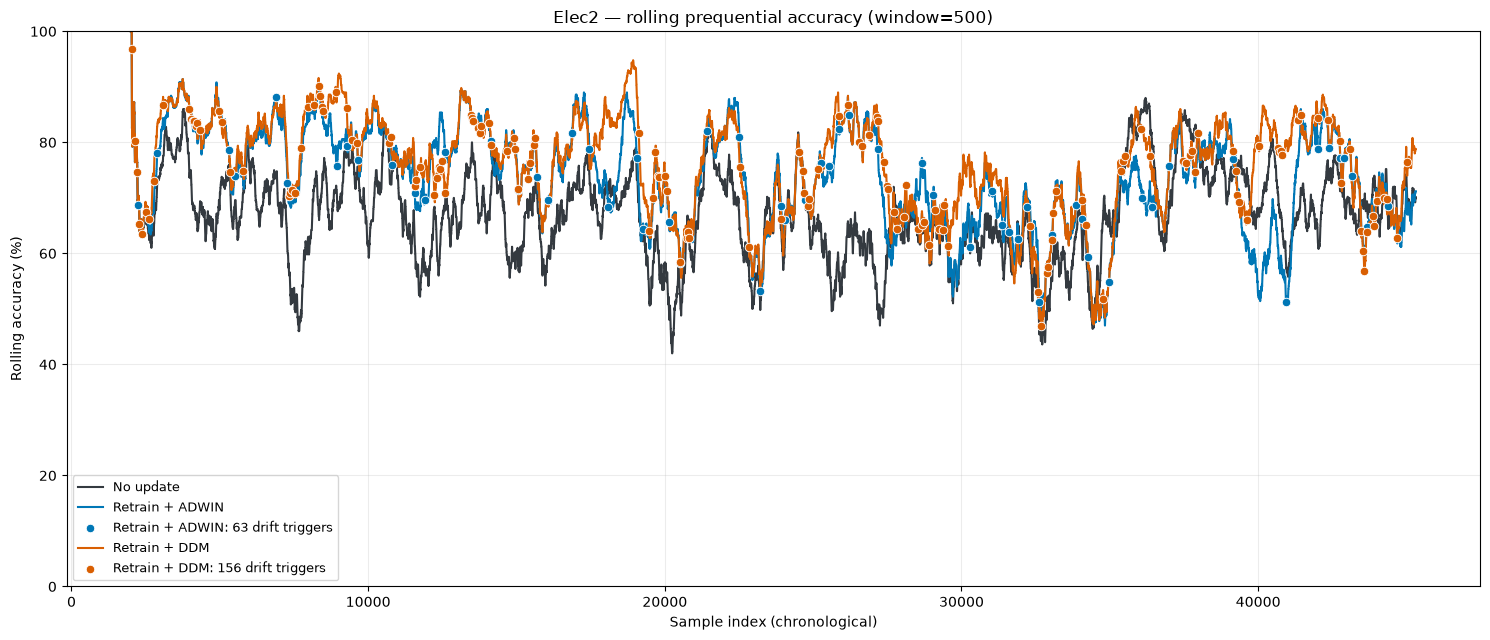

Saved: elec2_accuracy_drift.png


In [34]:
plot_df = results_df.copy()
plot_df["rolling_accuracy"] = plot_df.groupby("strategy", sort=False)["correct"].transform(
    lambda s: s.rolling(ACCURACY_WINDOW, min_periods=1).mean()
)

fig, ax = plt.subplots(figsize=(15, 6.5))
style = {
    "No update": ("#343a40", "-"),
    "Retrain + ADWIN": ("#0077b6", "-"),
    "Retrain + DDM": ("#d95f02", "-"),
}
for name, frame in plot_df.groupby("strategy", sort=False):
    col, ls = style[name]
    ax.plot(frame["index"], 100 * frame["rolling_accuracy"], color=col, ls=ls, lw=1.5, label=name)
    sub = update_events_df[update_events_df["strategy"] == name]
    if len(sub):
        points = frame.set_index("index")["rolling_accuracy"].reindex(sub["index"])
        ax.scatter(
            sub["index"],
            100 * points.to_numpy(),
            s=38,
            color=col,
            edgecolors="white",
            linewidths=0.65,
            zorder=5,
            label=f"{name}: {len(sub)} drift triggers",
        )

ax.set(
    title=f"Elec2 — rolling prequential accuracy (window={ACCURACY_WINDOW})",
    xlabel="Sample index (chronological)",
    ylabel="Rolling accuracy (%)",
)
ax.grid(alpha=0.23)
ax.set_ylim(0, 100)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.savefig("elec2_accuracy_drift.png", dpi=170, bbox_inches="tight")
plt.show()
print("Saved: elec2_accuracy_drift.png")

## 6. Biểu đồ detector — ADWIN và DDM trên cùng error stream

Đây là các điểm được phát hiện trong phần 3 khi mô hình reference học liên tục. Trục tung là accuracy rolling của mô hình reference, không phải nhánh adaptive. Hai đồ thị khác nhau do hai câu hỏi thực nghiệm khác nhau.

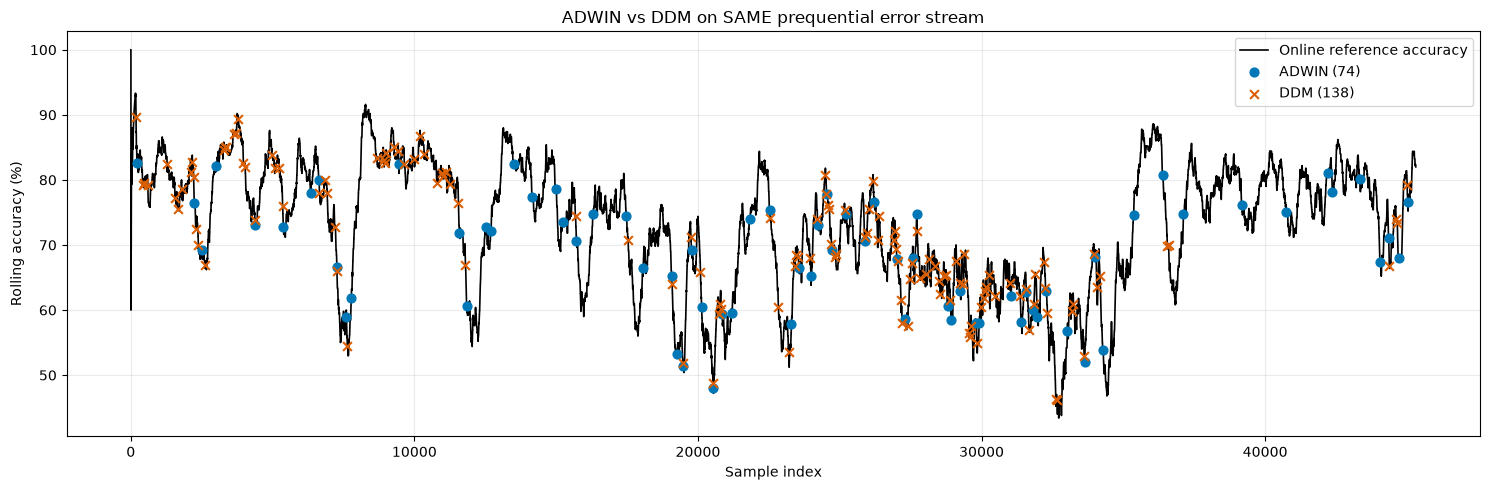

In [35]:
ref = reference_df.copy()
ref["rolling_accuracy"] = ref["correct"].rolling(ACCURACY_WINDOW, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    ref["index"],
    ref["rolling_accuracy"] * 100,
    c="black",
    lw=1.2,
    label="Online reference accuracy",
)
for name, color, marker in [("ADWIN", "#0077b6", "o"), ("DDM", "#d95f02", "x")]:
    subset = monitor_events_df[monitor_events_df["detector"] == name]
    ypoints = ref.set_index("index")["rolling_accuracy"].reindex(subset["index"])
    ax.scatter(
        subset["index"],
        ypoints * 100,
        label=f"{name} ({len(subset)})",
        color=color,
        marker=marker,
        s=40,
        zorder=5,
    )
ax.set(
    xlabel="Sample index",
    ylabel="Rolling accuracy (%)",
    title="ADWIN vs DDM on SAME prequential error stream",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig("elec2_detector_points.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. Kết luận tự động và giới hạn nghiên cứu

- **No-change baseline:** dùng nhãn mẫu trước; là benchmark chuỗi thời gian đơn giản, không dùng features.
- **Online reference:** học sau mỗi mẫu, đánh giá bằng test-then-train; dùng để so sánh ADWIN với DDM trên *cùng* luồng lỗi.
- **Frozen:** học trong warm-up, sau đó không học nữa.
- **Retrain:** chỉ tạo mô hình mới khi ADWIN/DDM báo drift, huấn luyện trên nhãn đã xuất hiện trong quá khứ.

**Hạn chế:** Elec2 không cung cấp ground-truth timestamps của concept drift; drift points chỉ là cảnh báo detector. Đây không phải phép đo detection-delay hay false-alarm chính thức. Việc đánh giá giả định nhãn có ngay sau dự đoán. Baseline no-change có 45.311 lượt dự đoán, còn so sánh ML chỉ chấm từ mẫu 2.001; không nên so sánh trực tiếp các accuracy khác window mà không chú thích.

**Ý nghĩa của kết quả:** Nếu retrain accuracy cao hơn frozen, có bằng chứng rằng cập nhật theo detector hữu ích *với cấu hình này*. Nếu thấp hơn, điều đó vẫn là kết quả hợp lệ: detector có thể báo drift không liên quan hiệu quả mô hình, hoặc retrain window chưa tối ưu. Không kết luận mọi concept drift đều đã được phát hiện.


In [36]:
frozen_acc = float(summary.loc[summary.strategy == "No update", "accuracy"].iloc[0])
print(f"No-change baseline (all possible steps): {baseline_acc:.2%}")
print(f"Online reference prequential: {reference_df.correct.mean():.2%}")
for _, row in summary.iterrows():
    print(f"{row['strategy']}: {row['accuracy']:.2%} | retrains: {row['retrain_count']}")
    if row["strategy"] != "No update":
        delta = row["accuracy"] - frozen_acc
        print(f"  Δ vs frozen: {delta:+.2%} points")
print("Detection locations reference:")
for k in ["ADWIN", "DDM"]:
    print(k, monitor_events_df.loc[monitor_events_df.detector == k, "index"].tolist())

No-change baseline (all possible steps): 85.33%
Online reference prequential: 72.87%
No update: 67.01% | retrains: 0
Retrain + ADWIN: 73.51% | retrains: 63
  Δ vs frozen: +6.50% points
Retrain + DDM: 75.81% | retrains: 156
  Δ vs frozen: +8.80% points
Detection locations reference:
ADWIN [225, 2241, 2497, 3009, 4385, 5377, 6337, 6625, 7265, 7585, 7777, 9473, 11585, 11841, 12513, 12705, 13505, 14145, 14977, 15233, 15713, 16289, 17473, 18049, 19073, 19265, 19489, 19777, 20129, 20545, 20833, 21185, 21825, 22529, 23297, 23553, 24001, 24225, 24545, 24737, 25217, 25889, 26209, 27009, 27297, 27585, 27713, 28801, 28929, 29249, 29793, 29921, 31041, 31393, 31585, 31809, 31969, 32257, 33025, 33633, 33985, 34273, 35361, 36385, 37121, 39169, 40737, 42209, 42369, 43329, 44065, 44353, 44705, 45025]
DDM [185, 415, 454, 599, 1278, 1557, 1658, 1797, 2136, 2173, 2216, 2292, 2380, 2614, 3296, 3328, 3361, 3641, 3708, 3775, 3970, 4028, 4378, 4976, 5068, 5234, 5354, 6652, 6832, 6924, 7191, 7270, 7635, 8671, 

## 8. Checklist nghiệm thu

- [x] Elec2 từ River, đánh giá theo thứ tự gốc.
- [x] No-change baseline = previous label, báo cáo accuracy.
- [x] ADWIN/DDM trên **cùng prequential 0/1 error stream**, ghi chỉ số mẫu phát hiện.
- [x] Frozen model và 2 nhánh retrain khi có drift; tránh dùng nhãn tương lai.
- [x] Accuracy over time và drift points, xuất PNG.
- [x] Báo cáo so sánh accuracy + retrain count.

**Nguồn tham khảo:** [River Elec2](https://riverml.xyz/), [River ADWIN implementation](https://github.com/online-ml/river/blob/main/river/drift/adwin.py), [River drift DDM](https://riverml.xyz/).

## 9. Task 2 — Unified benchmark: Accuracy, retraining frequency và CPU

Phần này chạy **độc lập** với các cell Task 1 phía trên, giữ nguyên output lịch sử của Task 1. Có thể bắt đầu từ cell import/config ngay dưới đây trong một kernel mới. Chỉ đọc cache Elec2 đã có; không tự tải dữ liệu, không ghi model, CSV, Markdown hoặc PNG ra đĩa. Các bảng, event records và biểu đồ mới được lưu trong output notebook.

**Mục tiêu:** so sánh Previous-label, Frozen GaussianNB, Retrain + ADWIN, Retrain + DDM và Periodic N=500/1.000/2.000 trên **cùng i=2.001…45.312**, sau 2.000 mẫu warmup. Tất cả nhánh GaussianNB dùng cùng learner, dữ liệu và cửa sổ retrain 2.000 mẫu. Online reference Task 1 là thí nghiệm khác, không được trộn vào bảng này.

Phiên bản Python/River và hash dataset của lần chạy Task 2 được in riêng. Chênh lệch với output Task 1 có thể liên quan environment/version, không tự quy kết nguyên nhân nếu chưa có controlled experiment. Giữ thứ tự CSV; `date` là feature chuẩn hóa, chưa phải chronology UTC đã xác minh. Nhãn được giả định có ngay sau prediction; không có ground-truth drift timestamps.

In [37]:
import csv
import hashlib
import json
import math
import os
import platform
import time
from collections import deque as t2_deque
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import river
from IPython.display import display
from river import datasets
from river import drift as t2_drift
from river import naive_bayes as t2_naive_bayes

T2_WARMUP = 2_000
T2_HISTORY = 2_000
T2_ROLLING = 500
T2_PERIODS = (500, 1_000, 2_000)
T2_ADWIN_DELTA = 0.002
T2_DDM_WARM_START = 30
T2_DATASET_SHA256 = "c10a416790ef8ab96089e5adfd2febb7c9cec72bd80dfecb2342f2283b86b88a"
T2_FEATURES = (
    "date",
    "day",
    "period",
    "nswprice",
    "nswdemand",
    "vicprice",
    "vicdemand",
    "transfer",
)

# Resolve an existing cache without invoking River's automatic download iterator.
t2_data_home = Path(os.path.expanduser(os.environ.get("RIVER_DATA", "~/river_data")))
t2_data_path = t2_data_home / "Elec2" / "electricity.csv"
if not t2_data_path.is_file():
    raise FileNotFoundError("Elec2 cache missing; Task 2 does not download or write datasets")
t2_data_bytes = t2_data_path.read_bytes()
t2_data_hash = hashlib.sha256(t2_data_bytes).hexdigest()
assert t2_data_hash == T2_DATASET_SHA256, "Different dataset snapshot; audit before comparing"
with t2_data_path.open(newline="") as handle:
    reader = csv.DictReader(handle)
    assert reader.fieldnames == [*T2_FEATURES, "class"]
    t2_samples = []
    for row in reader:
        assert row["class"] in {"UP", "DOWN"}
        x = {key: int(row[key]) if key == "day" else float(row[key]) for key in T2_FEATURES}
        assert all(math.isfinite(value) for value in x.values())
        t2_samples.append((x, row["class"] == "UP"))
assert len(t2_samples) == 45_312
assert len(t2_samples) - T2_WARMUP == 43_312


def t2_make_detector(kind):
    if kind == "ADWIN":
        return t2_drift.ADWIN(delta=T2_ADWIN_DELTA)
    if kind == "DDM":
        return t2_drift.binary.DDM(warm_start=T2_DDM_WARM_START)
    raise ValueError(f"Unsupported detector: {kind}")


t2_started_at = datetime.now(timezone.utc).isoformat()
t2_metadata = {
    "started_at_utc": t2_started_at,
    "python": platform.python_version(),
    "river": river.__version__,
    "packages": {name: version(name) for name in ("pandas", "numpy", "matplotlib")},
    "platform": platform.platform(),
    "machine": platform.machine(),
    "logical_cpu_count": os.cpu_count(),
    "dataset_path": str(t2_data_path),
    "dataset_sha256": t2_data_hash,
    "dataset_source": datasets.Elec2().url,
    "n_samples": len(t2_samples),
    "warmup": T2_WARMUP,
    "history": T2_HISTORY,
    "evaluation_start_inclusive": T2_WARMUP + 1,
    "evaluation_end_inclusive": len(t2_samples),
    "periods": list(T2_PERIODS),
    "adwin_parameters": t2_make_detector("ADWIN")._get_params(),
    "ddm_parameters": t2_make_detector("DDM")._get_params(),
    "cpu_clock": "time.process_time: model construction + learn_one loop only",
    "benchmark_repetitions": 1,
}
print(json.dumps(t2_metadata, indent=2, ensure_ascii=False))

{
  "started_at_utc": "2026-11-23T02:39:08.230175+00:00",
  "python": "3.11.11",
  "river": "0.22.0",
  "packages": {
    "pandas": "2.3.3",
    "numpy": "2.4.6",
    "matplotlib": "3.11.2"
  },
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.43",
  "machine": "x86_64",
  "logical_cpu_count": 8,
  "dataset_path": "/home/trggonos/river_data/Elec2/electricity.csv",
  "dataset_sha256": "c10a416790ef8ab96089e5adfd2febb7c9cec72bd80dfecb2342f2283b86b88a",
  "dataset_source": "https://maxhalford.github.io/files/datasets/electricity.zip",
  "n_samples": 45312,
  "warmup": 2000,
  "history": 2000,
  "evaluation_start_inclusive": 2001,
  "evaluation_end_inclusive": 45312,
  "periods": [
    500,
    1000,
    2000
  ],
  "adwin_parameters": {
    "delta": 0.002,
    "clock": 32,
    "max_buckets": 5,
    "min_window_length": 5,
    "grace_period": 10
  },
  "ddm_parameters": {
    "warm_start": 30,
    "warning_threshold": 2.0,
    "drift_threshold": 3.0
  },
  "cpu_clock": "time.proces

### 9.1. Protocol và ranh giới đo chi phí

1. Mọi model GaussianNB học cùng 2.000 mẫu đầu, được đo **warmup CPU riêng**. Previous-label khởi tạo từ y_2000, nên dự đoán đầu tiên ở i=2.001 dùng đúng nhãn trước đó.
2. Tại i: **predict → score → update detector → optional retrain → append (x_i,y_i) vào history**. Fresh model chỉ học các mẫu i−2.000…i−1 khi buffer đầy, không học nhãn i trước prediction hoặc trong lần retrain tại i. Sau warmup, frozen và các policy retrain không `learn_one` liên tục.
3. Periodic trigger theo `(i − 2000) % N == 0`, sau scoring. Lần đầu tại i=2.500/3.000/4.000; replacement chỉ ảnh hưởng prediction tiếp theo. Bỏ update sau observation cuối vì không còn prediction để đánh giá. ADWIN/DDM có detector riêng và reset sau replacement. Detector warm_start khác model warmup.
4. Timer `time.process_time()` bao **tạo fresh model + vòng learn_one**, gồm Python loop overhead, không gồm đọc CSV, predict, detector, DataFrame, vẽ hình hoặc I/O. Đo tại process thực thi; khác wall-clock time và không tự cộng CPU process con. Không chạy training song song.
5. Tổng CPU training = warmup + tổng CPU retrain. Mean CPU/retrain là N/A khi không có retrain. Baseline không có training; tổng 0 là tổng của không có thao tác train, không phải kết quả đo inference. Frozen có warmup được đo dù CPU retrain bằng 0.

Đây là **một lần đo** trên environment được in ở trên. CPU phụ thuộc máy, phiên bản và tải hệ thống; không suy kết luận thống kê hoặc production throughput từ một run. Các policy được chạy tuần tự; thứ tự và warm caches có thể ảnh hưởng timing. Không chỉnh tham số để ép một phương pháp thắng.

In [38]:
def t2_fit_window(rows, model_factory):
    """Time only construction and learning on an already materialized labeled window."""
    snapshot = tuple(rows)
    started_cpu = time.process_time()
    model = model_factory()
    for _, features, label in snapshot:
        model.learn_one(features, label)
    cpu_seconds = time.process_time() - started_cpu
    return model, cpu_seconds


def t2_evaluate_policy(
    samples,
    strategy,
    *,
    warmup=T2_WARMUP,
    history_size=T2_HISTORY,
    period=None,
    detector_kind=None,
    model_factory=None,
    detector_factory=None,
):
    """Evaluate one frozen/periodic/drift policy without using the current label to train."""
    if not 0 < warmup < len(samples) or history_size <= 0:
        raise ValueError("Require a positive warmup/history and nonempty evaluation interval")
    if period is not None and (not isinstance(period, int) or period <= 0):
        raise ValueError("period must be a positive integer")
    if period is not None and detector_kind is not None:
        raise ValueError("Periodic and detector triggers are separate benchmark policies")
    if model_factory is None:
        model_factory = t2_naive_bayes.GaussianNB
    if detector_factory is None:
        detector_factory = t2_make_detector

    warmup_rows = [(i, x, y) for i, (x, y) in enumerate(samples[:warmup], start=1)]
    model, warmup_cpu = t2_fit_window(warmup_rows, model_factory)
    past = t2_deque(warmup_rows, maxlen=history_size)
    detector = detector_factory(detector_kind) if detector_kind is not None else None
    predictions, events = [], []

    for i in range(warmup + 1, len(samples) + 1):
        features, label = samples[i - 1]
        prediction = model.predict_one(features)
        correct = int(prediction is not None and prediction == label)
        predictions.append((i, strategy, label, prediction, correct))
        detector_drift = False
        if detector is not None:
            detector.update(1 - correct)
            detector_drift = bool(detector.drift_detected)
        scheduled = period is not None and (i - warmup) % period == 0
        if i < len(samples) and (detector_drift or scheduled):
            # Strictly past observations: sample i is appended only below.
            assert past[-1][0] == i - 1
            assert len(past) == min(history_size, i - 1)
            model, cpu_seconds = t2_fit_window(past, model_factory)
            events.append(
                {
                    "strategy": strategy,
                    "index": i,
                    "evaluation_step": i - warmup,
                    "trigger_type": "drift" if detector_drift else "periodic",
                    "training_start_index": past[0][0],
                    "training_end_index": past[-1][0],
                    "training_samples": len(past),
                    "cpu_seconds": cpu_seconds,
                }
            )
            if detector is not None:
                detector = detector_factory(detector_kind)
        past.append((i, dict(features), label))
    return (
        predictions,
        events,
        {
            "strategy": strategy,
            "training_start_index": 1,
            "training_end_index": warmup,
            "training_samples": warmup,
            "cpu_seconds": warmup_cpu,
        },
    )


def t2_previous_label(samples, warmup=T2_WARMUP):
    previous_label = samples[warmup - 1][1]
    predictions = []
    for i in range(warmup + 1, len(samples) + 1):
        label = samples[i - 1][1]
        predictions.append(
            (i, "Previous-label", label, previous_label, int(previous_label == label))
        )
        previous_label = label
    return predictions

### 9.2. Kiểm tra protocol trước khi benchmark

Kiểm tra dưới đây dùng learner giả rất nhỏ để xác minh **prediction xảy ra trước learning**, cửa sổ retrain kết thúc ở i−1, periodic không trigger tại warmup, không update sau mẫu cuối, detector được reset sau drift. Đây là kiểm tra trình tự, không sinh số liệu accuracy/CPU của benchmark.

In [39]:
class T2OrderCheckingModel:
    def __init__(self):
        self.last_seen = 0
        self.label = False

    def learn_one(self, features, label):
        assert features["step"] > self.last_seen
        self.last_seen = features["step"]
        self.label = label

    def predict_one(self, features):
        assert self.last_seen < features["step"], "Current/future label leaked before prediction"
        return self.label


class T2AlwaysDrift:
    drift_detected = False

    def update(self, error):
        assert error in (0, 1)
        self.drift_detected = True


t2_toy = [({"step": i}, bool(i % 2)) for i in range(1, 11)]
t2_toy_predictions, t2_toy_events, _ = t2_evaluate_policy(
    t2_toy,
    "periodic-check",
    warmup=2,
    history_size=2,
    period=3,
    model_factory=T2OrderCheckingModel,
)
assert [row[0] for row in t2_toy_predictions] == list(range(3, 11))
assert [event["index"] for event in t2_toy_events] == [5, 8]
assert [(e["training_start_index"], e["training_end_index"]) for e in t2_toy_events] == [
    (3, 4),
    (6, 7),
]
t2_reset_calls = []


def t2_toy_detector_factory(kind):
    t2_reset_calls.append(kind)
    return T2AlwaysDrift()


_, t2_drift_check_events, _ = t2_evaluate_policy(
    t2_toy,
    "drift-check",
    warmup=2,
    history_size=2,
    detector_kind="test",
    model_factory=T2OrderCheckingModel,
    detector_factory=t2_toy_detector_factory,
)
assert [event["index"] for event in t2_drift_check_events] == list(range(3, 10))
assert len(t2_reset_calls) == 1 + len(t2_drift_check_events)
_, t2_no_events, _ = t2_evaluate_policy(
    t2_toy,
    "frozen-check",
    warmup=2,
    history_size=2,
    model_factory=T2OrderCheckingModel,
)
assert not t2_no_events
assert t2_previous_label(t2_toy, warmup=2)[0][3] == t2_toy[1][1]
print(
    "PASS: test-before-train, strict history, periodic schedule, last-sample guard, detector reset"
)

PASS: test-before-train, strict history, periodic schedule, last-sample guard, detector reset


### 9.3. Chạy benchmark thống nhất và kiểm tra kết quả

Các con số trong bảng được tính từ prediction/event records của lần chạy này, không sao chép accuracy Task 1. `delta_vs_frozen_pp` là **điểm phần trăm**. `retrain_cpu_mean_s` chỉ trung bình những lần retrain, không gộp warmup. Mỗi policy phải có cùng 43.312 index và label; các assertions kiểm tra count, schedule, cửa sổ lịch sử và tổng CPU.

In [40]:
t2_policy_configs = [
    ("Frozen GaussianNB", {}),
    ("Retrain + ADWIN", {"detector_kind": "ADWIN"}),
    ("Retrain + DDM", {"detector_kind": "DDM"}),
    *[(f"Periodic N={period}", {"period": period}) for period in T2_PERIODS],
]
t2_prediction_rows = t2_previous_label(t2_samples)
t2_event_rows, t2_warmup_rows = [], []
for t2_name, t2_config in t2_policy_configs:
    print(f"Running {t2_name} ...", flush=True)
    t2_rows, t2_events, t2_warmup = t2_evaluate_policy(t2_samples, t2_name, **t2_config)
    t2_prediction_rows.extend(t2_rows)
    t2_event_rows.extend(t2_events)
    t2_warmup_rows.append(t2_warmup)
    print(f"Finished {t2_name}: {len(t2_events)} retrains", flush=True)

t2_predictions = pd.DataFrame(
    t2_prediction_rows, columns=["index", "strategy", "label", "prediction", "correct"]
)
t2_retrain_events = pd.DataFrame(
    t2_event_rows,
    columns=[
        "strategy",
        "index",
        "evaluation_step",
        "trigger_type",
        "training_start_index",
        "training_end_index",
        "training_samples",
        "cpu_seconds",
    ],
)
t2_warmup_events = pd.DataFrame(t2_warmup_rows)
t2_strategy_order = ["Previous-label", *[name for name, _ in t2_policy_configs]]
t2_summary_rows = []
for t2_name in t2_strategy_order:
    rows = t2_predictions.loc[t2_predictions.strategy.eq(t2_name)]
    events = t2_retrain_events.loc[t2_retrain_events.strategy.eq(t2_name)]
    warmup_rows = t2_warmup_events.loc[t2_warmup_events.strategy.eq(t2_name)]
    warmup_cpu = float(warmup_rows.cpu_seconds.sum())
    retrain_cpu = float(events.cpu_seconds.sum())
    t2_summary_rows.append(
        {
            "strategy": t2_name,
            "n_eval": len(rows),
            "n_correct": int(rows.correct.sum()),
            "accuracy_pct": 100 * float(rows.correct.mean()),
            "retrain_count": len(events),
            "retrains_per_10000": 10000 * len(events) / len(rows),
            "warmup_cpu_s": warmup_cpu,
            "retrain_cpu_total_s": retrain_cpu,
            "retrain_cpu_mean_s": float(events.cpu_seconds.mean()) if len(events) else np.nan,
            "retrain_cpu_min_s": float(events.cpu_seconds.min()) if len(events) else np.nan,
            "retrain_cpu_max_s": float(events.cpu_seconds.max()) if len(events) else np.nan,
            "training_cpu_total_s": warmup_cpu + retrain_cpu,
        }
    )
t2_summary = pd.DataFrame(t2_summary_rows)
t2_frozen_pct = float(
    t2_summary.loc[t2_summary.strategy.eq("Frozen GaussianNB"), "accuracy_pct"].iloc[0]
)
t2_summary["delta_vs_frozen_pp"] = t2_summary.accuracy_pct - t2_frozen_pct

# Validate matched observations independently of policy outcomes.
t2_expected_indices = list(range(T2_WARMUP + 1, len(t2_samples) + 1))
t2_expected_labels = [label for _, label in t2_samples[T2_WARMUP:]]
for t2_name, rows in t2_predictions.groupby("strategy", sort=False):
    assert rows["index"].tolist() == t2_expected_indices
    assert rows.label.tolist() == t2_expected_labels
    assert rows.prediction.notna().all(), f"Uninitialized predictor after warmup: {t2_name}"
    assert rows.correct.tolist() == rows.prediction.eq(rows.label).astype(int).tolist()
assert t2_summary.n_eval.eq(43_312).all() and len(t2_summary) == 7
assert len(t2_predictions) == 7 * 43_312
assert t2_summary.loc[t2_summary.strategy.eq("Previous-label"), "n_correct"].iloc[0] == 36_945
assert not t2_retrain_events.strategy.eq("Frozen GaussianNB").any()
assert (t2_retrain_events.training_end_index == t2_retrain_events["index"] - 1).all()
assert (t2_retrain_events.training_start_index == t2_retrain_events["index"] - T2_HISTORY).all()
assert t2_retrain_events.training_samples.eq(T2_HISTORY).all()
assert t2_retrain_events["index"].between(T2_WARMUP + 1, len(t2_samples) - 1).all()
assert np.isfinite(t2_retrain_events.cpu_seconds).all()
assert t2_retrain_events.cpu_seconds.ge(0).all()
for period in T2_PERIODS:
    actual = t2_retrain_events.loc[t2_retrain_events.strategy.eq(f"Periodic N={period}"), "index"]
    expected = list(range(T2_WARMUP + period, len(t2_samples), period))
    assert actual.tolist() == expected
for row in t2_summary.to_dict(orient="records"):
    measured = t2_retrain_events.loc[t2_retrain_events.strategy.eq(row["strategy"]), "cpu_seconds"]
    assert math.isclose(row["retrain_cpu_total_s"], float(measured.sum()), abs_tol=1e-12)
    assert row["retrain_count"] == len(measured)
    if len(measured):
        assert math.isclose(row["retrain_cpu_mean_s"], float(measured.mean()), abs_tol=1e-12)
assert t2_warmup_events.training_samples.eq(T2_WARMUP).all()
assert np.isfinite(t2_warmup_events.cpu_seconds).all()
print("PASS: matched interval/labels, baseline, no leakage, periodic counts, CPU accounting")
print(t2_summary.round(6).to_string(index=False))
display(t2_summary.round(6))

Running Frozen GaussianNB ...
Finished Frozen GaussianNB: 0 retrains
Running Retrain + ADWIN ...
Finished Retrain + ADWIN: 63 retrains
Running Retrain + DDM ...
Finished Retrain + DDM: 156 retrains
Running Periodic N=500 ...
Finished Periodic N=500: 86 retrains
Running Periodic N=1000 ...
Finished Periodic N=1000: 43 retrains
Running Periodic N=2000 ...
Finished Periodic N=2000: 21 retrains
PASS: matched interval/labels, baseline, no leakage, periodic counts, CPU accounting
         strategy  n_eval  n_correct  accuracy_pct  retrain_count  retrains_per_10000  warmup_cpu_s  retrain_cpu_total_s  retrain_cpu_mean_s  retrain_cpu_min_s  retrain_cpu_max_s  training_cpu_total_s  delta_vs_frozen_pp
   Previous-label   43312      36945     85.299686              0            0.000000      0.000000             0.000000                 NaN                NaN                NaN              0.000000           18.292852
Frozen GaussianNB   43312      29022     67.006834              0            0.

,strategy,n_eval,n_correct,accuracy_pct,retrain_count,retrains_per_10000,warmup_cpu_s,retrain_cpu_total_s,retrain_cpu_mean_s,retrain_cpu_min_s,retrain_cpu_max_s,training_cpu_total_s,delta_vs_frozen_pp
0,Previous-label,43312,36945,85.299686,0,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000,18.292852
1,Frozen GaussianNB,43312,29022,67.006834,0,0.000000,0.011232,0.000000,NaN,NaN,NaN,0.011232,0.000000
2,Retrain + ADWIN,43312,31839,73.510805,63,14.545622,0.008875,0.496416,0.007880,0.007091,0.009878,0.505291,6.503971
3,Retrain + DDM,43312,32833,75.805781,156,36.017732,0.008170,1.250087,0.008013,0.007245,0.013883,1.258256,8.798947
4,Periodic N=500,43312,32550,75.152383,86,19.855929,0.009642,0.703973,0.008186,0.007368,0.013899,0.713615,8.145549
5,Periodic N=1000,43312,32266,74.496675,43,9.927965,0.008121,0.346127,0.008049,0.007314,0.010650,0.354248,7.489841
6,Periodic N=2000,43312,32128,74.178057,21,4.848541,0.008943,0.168624,0.008030,0.007186,0.010779,0.177567,7.171223


### 9.4. Warmup CPU, chi phí từng retrain và artifact trong notebook

`t2_retrain_events` giữ từng trigger, cửa sổ training và CPU seconds; `t2_warmup_events` tách khởi tạo. Bảng dưới có thể rút gọn để xem, nhưng **JSON output lưu đầy đủ** summary, warmup, retrain events và bitstrings correctness/prediction của cả bảy policy. Mỗi bit ứng với một index từ 2.001 đến 45.312; actual labels được lưu một lần. Có thể kiểm toán accuracy và rolling curves từ output mà không huấn luyện lại. Không xuất file bên ngoài notebook.

In [41]:
print("Warmup CPU (separate from retraining):")
display(t2_warmup_events)
print(f"Per-retrain CPU: {len(t2_retrain_events)} complete events in JSON output below")
display(t2_retrain_events)
t2_saved_predictions = {}
for t2_name in t2_strategy_order:
    rows = t2_predictions.loc[t2_predictions.strategy.eq(t2_name)]
    t2_saved_predictions[t2_name] = {
        "correctness_bits": "".join(str(int(value)) for value in rows.correct),
        "prediction_bits": "".join(str(int(value)) for value in rows.prediction),
    }
t2_artifact = {
    "schema_version": 1,
    "metadata": t2_metadata,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "summary": json.loads(t2_summary.to_json(orient="records", double_precision=15)),
    "warmup_events": t2_warmup_events.to_dict(orient="records"),
    "retrain_events": t2_retrain_events.to_dict(orient="records"),
    "label_bits": "".join(str(int(value)) for value in t2_expected_labels),
    "predictions": t2_saved_predictions,
}
# Reject NaN/Infinity in the durable payload; missing means are JSON null.
json.dumps(t2_artifact, allow_nan=False)
display({"application/json": t2_artifact}, raw=True)

Warmup CPU (separate from retraining):


,strategy,training_start_index,training_end_index,training_samples,cpu_seconds
0,Frozen GaussianNB,1,2000,2000,0.011232
1,Retrain + ADWIN,1,2000,2000,0.008875
2,Retrain + DDM,1,2000,2000,0.008170
3,Periodic N=500,1,2000,2000,0.009642
4,Periodic N=1000,1,2000,2000,0.008121
5,Periodic N=2000,1,2000,2000,0.008943


Per-retrain CPU: 369 complete events in JSON output below


,strategy,index,evaluation_step,trigger_type,training_start_index,training_end_index,training_samples,cpu_seconds
0,Retrain + ADWIN,2256,256,drift,256,2255,2000,0.007500
1,Retrain + ADWIN,2896,896,drift,896,2895,2000,0.007498
2,Retrain + ADWIN,5296,3296,drift,3296,5295,2000,0.007622
3,Retrain + ADWIN,5520,3520,drift,3520,5519,2000,0.008025
4,Retrain + ADWIN,6896,4896,drift,4896,6895,2000,0.007845
...,...,...,...,...,...,...,...,...
364,Periodic N=2000,36000,34000,periodic,34000,35999,2000,0.007655
365,Periodic N=2000,38000,36000,periodic,36000,37999,2000,0.007186
366,Periodic N=2000,40000,38000,periodic,38000,39999,2000,0.007624
367,Periodic N=2000,42000,40000,periodic,40000,41999,2000,0.007627


### 9.5. Accuracy theo thứ tự quan sát và Accuracy–CPU–Frequency

Rolling accuracy dùng đủ 500 prediction (`min_periods=500`); cumulative accuracy chỉ tính phần sau warmup. CPU plots biểu diễn training process time, **không phải end-to-end latency**. Các hình được display inline và đóng sau đó; không gọi `savefig` tới đường dẫn PNG.

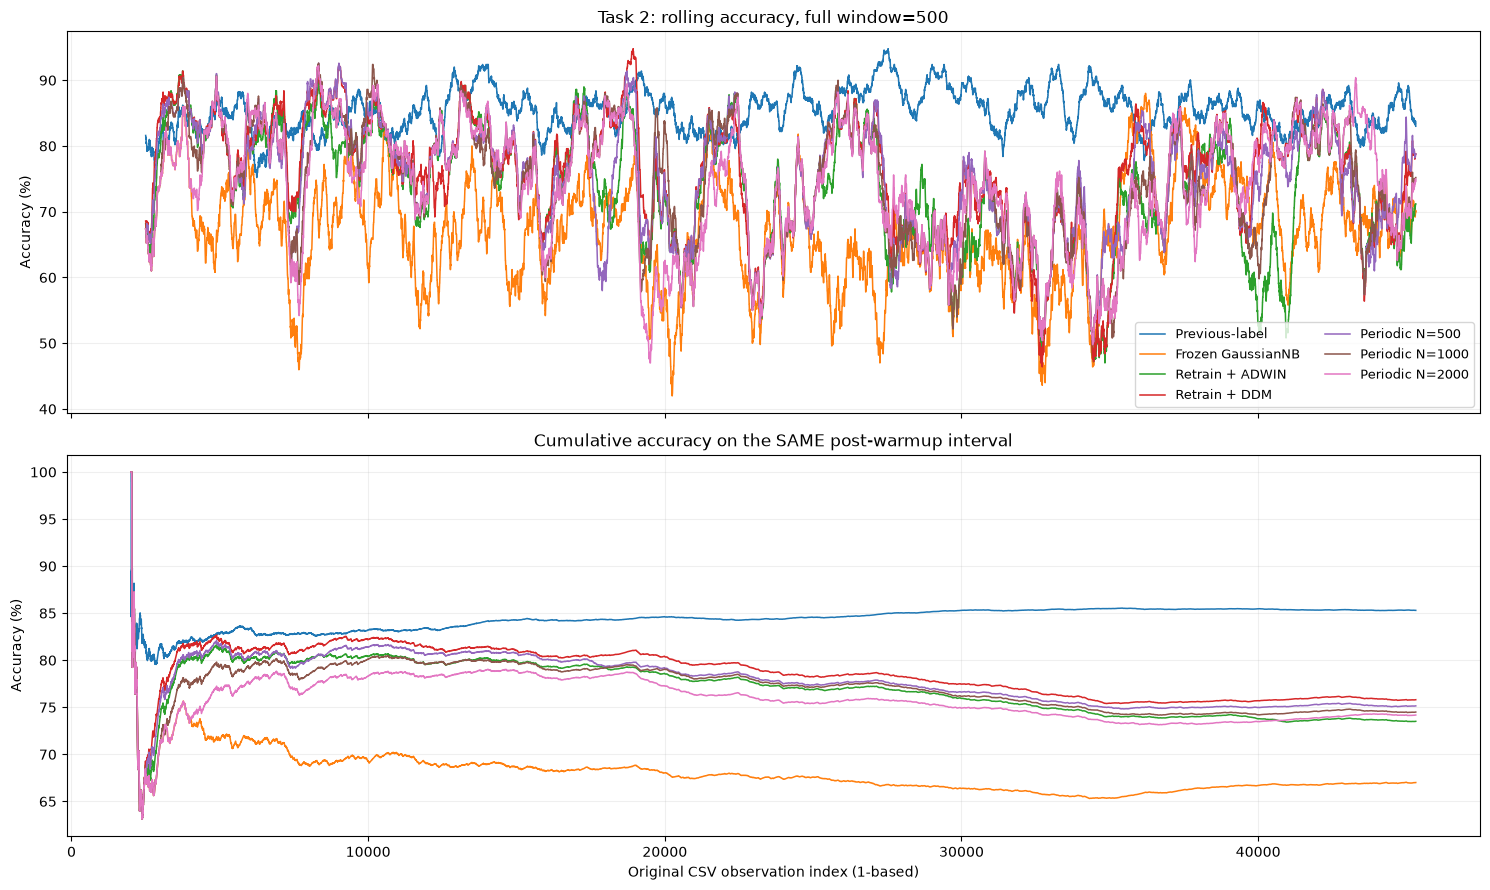

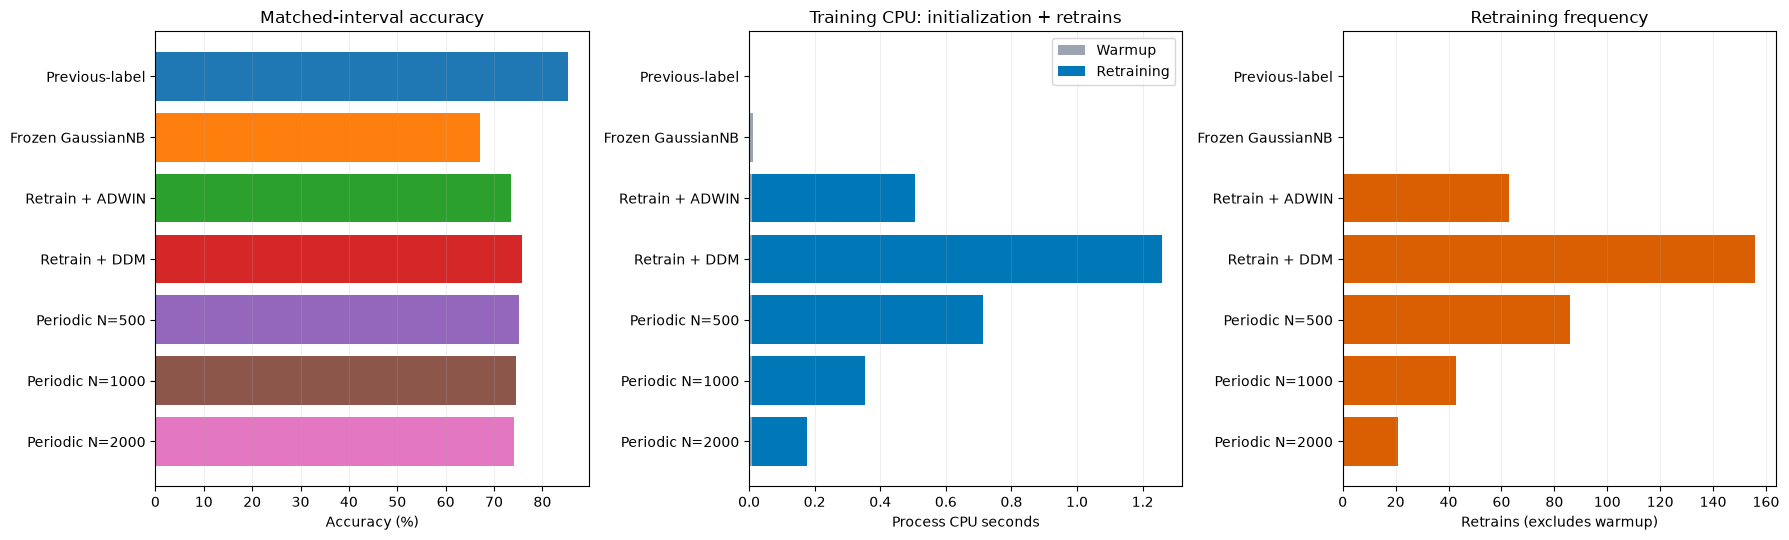

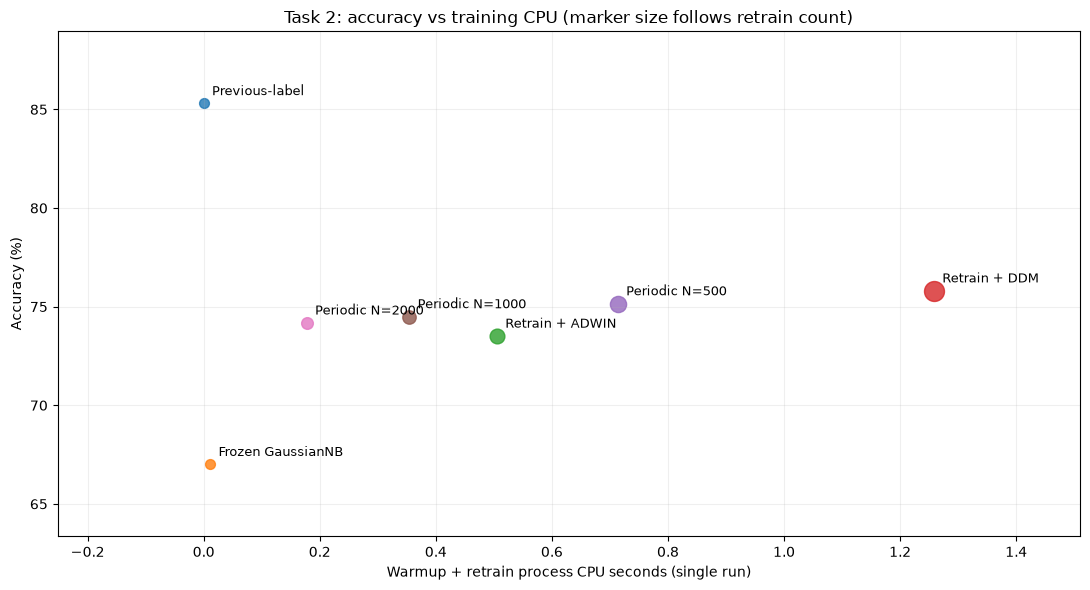

In [42]:
t2_plot = t2_predictions.copy()
t2_plot["rolling_pct"] = t2_plot.groupby("strategy", sort=False).correct.transform(
    lambda values: 100 * values.rolling(T2_ROLLING, min_periods=T2_ROLLING).mean()
)
t2_plot["cumulative_pct"] = t2_plot.groupby("strategy", sort=False).correct.transform(
    lambda values: 100 * values.expanding().mean()
)
t2_colors = dict(zip(t2_strategy_order, plt.get_cmap("tab10").colors))
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
for name in t2_strategy_order:
    rows = t2_plot.loc[t2_plot.strategy.eq(name)]
    for ax, metric in zip(axes, ["rolling_pct", "cumulative_pct"]):
        ax.plot(rows["index"], rows[metric], color=t2_colors[name], lw=1.1, label=name)
axes[0].set_title(f"Task 2: rolling accuracy, full window={T2_ROLLING}")
axes[1].set_title("Cumulative accuracy on the SAME post-warmup interval")
for ax in axes:
    ax.set_ylabel("Accuracy (%)")
    ax.grid(alpha=0.2)
axes[0].legend(ncol=2, fontsize=9)
axes[1].set_xlabel("Original CSV observation index (1-based)")
fig.tight_layout()
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
positions = np.arange(len(t2_summary))
labels = t2_summary.strategy.tolist()
axes[0].barh(positions, t2_summary.accuracy_pct, color=[t2_colors[n] for n in labels])
axes[0].set_title("Matched-interval accuracy")
axes[0].set_xlabel("Accuracy (%)")
axes[1].barh(positions, t2_summary.warmup_cpu_s, label="Warmup", color="#9aa5b1")
axes[1].barh(
    positions,
    t2_summary.retrain_cpu_total_s,
    left=t2_summary.warmup_cpu_s,
    label="Retraining",
    color="#0077b6",
)
axes[1].set_title("Training CPU: initialization + retrains")
axes[1].set_xlabel("Process CPU seconds")
axes[1].legend()
axes[2].barh(positions, t2_summary.retrain_count, color="#d95f02")
axes[2].set_title("Retraining frequency")
axes[2].set_xlabel("Retrains (excludes warmup)")
for ax in axes:
    ax.set_yticks(positions, labels)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 6))
for row in t2_summary.to_dict(orient="records"):
    ax.scatter(
        row["training_cpu_total_s"],
        row["accuracy_pct"],
        s=50 + row["retrain_count"],
        color=t2_colors[row["strategy"]],
        alpha=0.8,
    )
    ax.annotate(
        row["strategy"],
        (row["training_cpu_total_s"], row["accuracy_pct"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
    )
ax.set(
    title="Task 2: accuracy vs training CPU (marker size follows retrain count)",
    xlabel="Warmup + retrain process CPU seconds (single run)",
    ylabel="Accuracy (%)",
)
ax.margins(x=0.2, y=0.2)
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)

### 9.6. Kết luận từ lần chạy này

Cell dưới sinh nhận xét từ số liệu chưa làm tròn. Gain dương/âm đều được giữ nguyên. ADWIN/DDM là detectors; retrain là policy. Nhiều alerts/retrains không chứng minh detection quality. Accuracy cao hơn frozen chưa chứng minh vượt baseline hoặc periodic. Cost ratio chỉ mô tả lần đo này; không kết luận quan hệ nhân quả hoặc khả năng production.

In [43]:
t2_adaptive = t2_summary.loc[t2_summary.strategy.isin(["Retrain + ADWIN", "Retrain + DDM"])]
t2_periodic = t2_summary.loc[t2_summary.strategy.str.startswith("Periodic")]
t2_best_adaptive = t2_adaptive.loc[t2_adaptive.accuracy_pct.idxmax()]
t2_best_periodic = t2_periodic.loc[t2_periodic.accuracy_pct.idxmax()]
t2_baseline = t2_summary.loc[t2_summary.strategy.eq("Previous-label")].iloc[0]
print(f"Evaluation: {T2_WARMUP + 1}..{len(t2_samples)}, n={len(t2_expected_indices)} per policy")
print(
    f"Previous-label: {t2_baseline.n_correct}/{t2_baseline.n_eval} = {t2_baseline.accuracy_pct:.4f}%"
)
for row in t2_summary.to_dict(orient="records"):
    print(
        f"{row['strategy']}: accuracy={row['accuracy_pct']:.4f}% | "
        f"delta vs frozen={row['delta_vs_frozen_pp']:+.4f} pp | "
        f"retrains={row['retrain_count']} | training CPU={row['training_cpu_total_s']:.6f}s"
    )
print("\nAccuracy comparison (no claim of universal policy superiority):")
print(
    f"Best adaptive in this run: {t2_best_adaptive.strategy} ({t2_best_adaptive.accuracy_pct:.4f}%)"
)
print(
    f"Best periodic in this run: {t2_best_periodic.strategy} ({t2_best_periodic.accuracy_pct:.4f}%)"
)
t2_accuracy_gap = t2_best_adaptive.accuracy_pct - t2_best_periodic.accuracy_pct
print(f"Best adaptive minus best periodic: {t2_accuracy_gap:+.4f} percentage points")
print(
    "Training CPU for those two policies: "
    f"{t2_best_adaptive.training_cpu_total_s:.6f}s vs {t2_best_periodic.training_cpu_total_s:.6f}s"
)
print(
    "\nSingle-run CPU timings; no drift ground truth, delayed-label, memory, latency or throughput test."
)
print(
    "Task 1 outputs above are historical; Task 2 uses its own logged environment and dataset hash."
)

Evaluation: 2001..45312, n=43312 per policy
Previous-label: 36945/43312 = 85.2997%
Previous-label: accuracy=85.2997% | delta vs frozen=+18.2929 pp | retrains=0 | training CPU=0.000000s
Frozen GaussianNB: accuracy=67.0068% | delta vs frozen=+0.0000 pp | retrains=0 | training CPU=0.011232s
Retrain + ADWIN: accuracy=73.5108% | delta vs frozen=+6.5040 pp | retrains=63 | training CPU=0.505291s
Retrain + DDM: accuracy=75.8058% | delta vs frozen=+8.7989 pp | retrains=156 | training CPU=1.258256s
Periodic N=500: accuracy=75.1524% | delta vs frozen=+8.1455 pp | retrains=86 | training CPU=0.713615s
Periodic N=1000: accuracy=74.4967% | delta vs frozen=+7.4898 pp | retrains=43 | training CPU=0.354248s
Periodic N=2000: accuracy=74.1781% | delta vs frozen=+7.1712 pp | retrains=21 | training CPU=0.177567s

Accuracy comparison (no claim of universal policy superiority):
Best adaptive in this run: Retrain + DDM (75.8058%)
Best periodic in this run: Periodic N=500 (75.1524%)
Best adaptive minus best per

### 9.7. Nghiệm thu Task 2 và giới hạn

- [x] Previous-label và sáu model policies cùng warmup/scoring interval; baseline đối chiếu độc lập 36.945/43.312.
- [x] Frozen, ADWIN, DDM và Periodic N=500/1.000/2.000; không thay learner/hyperparameters để cải thiện kết quả.
- [x] Strict historical window, test-before-train, reset detector và schedule được kiểm tra bằng toy protocol tests cùng assertions trên run thật.
- [x] Warmup CPU riêng; per-retrain CPU, total/mean/min/max, retrain frequency và accuracy gain được tính từ records.
- [x] Full event/compact prediction payload và ba biểu đồ được nhúng trong notebook; không tạo artifact ngoài tệp này.

**Giới hạn:** một run, một dataset, nhãn đến ngay; không có drift ground truth, đánh giá false alarms/detection delay hay statistical significance. Chưa đo memory, latency, throughput, delayed labels hoặc triển khai production. CPU chỉ đo training process, không bao inference/detector/I/O. Cần repeated benchmarks và một final holdout/stream độc lập trước chọn policy vận hành. Thứ tự CSV được giữ nguyên; không sửa dữ liệu chuẩn hóa hoặc tự dựng UTC chronology. Phần Task 1 phía trên giữ nguyên vì có output lịch sử chạy với environment khác.

## 10. Case tích hợp Elec2 — MinIO và MLflow

Dùng kết quả Task 2 đã lưu; không chạy lại benchmark hay thay accuracy/CPU. Có thể bắt đầu tại cell cấu hình bên dưới trong environment River của Task 2. Client dùng Boto3 và MLflow REST API, không cần cài MLflow SDK.

Luồng: cache Elec2 → Parquet versioned trên MinIO → đọc lại qua S3 → log bảy policy vào MLflow → tái dựng final model snapshot từ training window đã ghi → kiểm tra model round-trip → đăng ký candidate. Artifacts remote và output notebook là đầu ra; không tạo CSV/model/PNG local, không sửa hạ tầng hoặc đổi champion.

Keys/runs gắn với SHA-256. Chạy lại cùng snapshot reuse identity và kiểm tra nội dung cũ; khác checksum thì dừng thay vì overwrite.

**Trạng thái bản khôi phục:** code tích hợp đã được bổ sung lại; output tích hợp để trống vì kết quả Task 2 hiện tại khác snapshot trước. Chạy lần lượt sáu code cell của mục 10 trong kernel `.venv` để kiểm chứng với benchmark đang lưu.


In [ ]:
import base64
import csv
import hashlib
import io
import json
import math
import os
import pickle
import platform
import time as m3_time
from importlib.metadata import version
from pathlib import Path
from urllib.parse import quote

import boto3
import numpy as np
import pandas as pd
import requests
import yaml
from botocore.exceptions import ClientError
from dotenv import dotenv_values
from river import naive_bayes as m3_naive_bayes

M3_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "docker-compose.yml").is_file()
)
M3_NOTEBOOK = M3_ROOT / "notebooks/Elec2_Label_Based_Drift_Detection.ipynb"
m3_nb = json.loads(M3_NOTEBOOK.read_text())
m3_saved_results = [
    output["data"]["application/json"]
    for cell in m3_nb["cells"]
    for output in cell.get("outputs", [])
    if "application/json" in output.get("data", {})
    and {"summary", "predictions", "retrain_events"}.issubset(output["data"]["application/json"])
]
assert len(m3_saved_results) == 1, "Run and save Task 2 before integration"
m3_results = globals().get("t2_artifact", m3_saved_results[0])
assert len(m3_results["summary"]) == 7
assert version("river") == m3_results["metadata"]["river"], (
    "Use the River version recorded by Task 2"
)
M3_FEATURES = (
    "date",
    "day",
    "period",
    "nswprice",
    "nswdemand",
    "vicprice",
    "vicdemand",
    "transfer",
)
M3_EXPERIMENT = "elec2_label_based_drift"
M3_REGISTERED_MODEL = "elec2-gaussian-nb"
m3_local = dotenv_values(M3_ROOT / ".env") if (M3_ROOT / ".env").is_file() else {}
m3_credentials = m3_local or dotenv_values(M3_ROOT / ".env.example")
M3_MINIO_ENDPOINT = (
    os.environ.get("MINIO_ENDPOINT") or m3_local.get("MINIO_ENDPOINT") or "http://127.0.0.1:19000"
)
M3_TRACKING_URI = (
    os.environ.get("MLFLOW_TRACKING_URI")
    or m3_local.get("MLFLOW_TRACKING_URI")
    or "http://127.0.0.1:5000"
).rstrip("/")
m3_s3 = boto3.client(
    "s3",
    endpoint_url=M3_MINIO_ENDPOINT,
    aws_access_key_id=os.environ.get("MINIO_ROOT_USER")
    or os.environ.get("AWS_ACCESS_KEY_ID")
    or m3_credentials.get("MINIO_ROOT_USER"),
    aws_secret_access_key=os.environ.get("MINIO_ROOT_PASSWORD")
    or os.environ.get("AWS_SECRET_ACCESS_KEY")
    or m3_credentials.get("MINIO_ROOT_PASSWORD"),
    region_name=os.environ.get("AWS_DEFAULT_REGION", "us-east-1"),
)
m3_http = requests.Session()
m3_health = m3_http.get(f"{M3_TRACKING_URI}/health", timeout=10)
m3_health.raise_for_status()
m3_version_response = m3_http.get(f"{M3_TRACKING_URI}/version", timeout=10)
m3_version_response.raise_for_status()
M3_MLFLOW_VERSION = m3_version_response.text.strip()
m3_buckets = {item["Name"] for item in m3_s3.list_buckets()["Buckets"]}
assert {"raw", "models", "mlflow"}.issubset(m3_buckets)


def m3_json_bytes(value):
    return json.dumps(
        value, ensure_ascii=False, sort_keys=True, allow_nan=False, separators=(",", ":")
    ).encode()


def m3_api(method, endpoint, *, body=None, params=None):
    response = m3_http.request(
        method, f"{M3_TRACKING_URI}/api/2.0/mlflow/{endpoint}", json=body, params=params, timeout=30
    )
    response.raise_for_status()
    return response.json() if response.content else {}


def m3_put_immutable(bucket, key, content, content_type):
    """Create missing objects conditionally; refuse existing content that differs."""
    try:
        response = m3_s3.get_object(Bucket=bucket, Key=key)
    except ClientError as error:
        if error.response["Error"]["Code"] not in {"NoSuchKey", "404", "NotFound"}:
            raise
        try:
            m3_s3.put_object(
                Bucket=bucket,
                Key=key,
                Body=content,
                ContentType=content_type,
                Metadata={"sha256": hashlib.sha256(content).hexdigest()},
                IfNoneMatch="*",
            )
        except ClientError as race:
            if race.response["Error"]["Code"] not in {"PreconditionFailed", "412"}:
                raise
        response = m3_s3.get_object(Bucket=bucket, Key=key)
    with response["Body"] as stream:
        actual = stream.read()
    assert actual == content, f"Immutable object mismatch: s3://{bucket}/{key}"
    return hashlib.sha256(actual).hexdigest()


def m3_artifact_url(run, path):
    uri = run["info"]["artifact_uri"]
    assert uri.startswith("mlflow-artifacts:/"), "Artifact proxy mode required"
    prefix = uri.split(":", 1)[1].strip("/")
    return f"{M3_TRACKING_URI}/api/2.0/mlflow-artifacts/artifacts/{quote(prefix + '/' + path, safe='/')}"


def m3_put_artifact(run, path, content, content_type="application/json"):
    # Listing distinguishes absent files from server/auth errors. MLflow S3 GET
    # may return HTTP 500 for a missing object; never treat generic 500 as absent.
    parent_path = path.rpartition("/")[0]
    listing = m3_api(
        "GET", "artifacts/list", params={"run_id": run["info"]["run_id"], "path": parent_path}
    )
    exists = any(
        item["path"] == path and not item.get("is_dir", False) for item in listing.get("files", [])
    )
    url = m3_artifact_url(run, path)
    if not exists:
        uploaded = m3_http.put(
            url, data=content, headers={"Content-Type": content_type}, timeout=30
        )
        uploaded.raise_for_status()
    response = m3_http.get(url, timeout=30)
    response.raise_for_status()
    assert response.content == content, f"Artifact round-trip mismatch: {path}"
    return hashlib.sha256(response.content).hexdigest()


M3_RESULTS_BYTES = m3_json_bytes(m3_results)
M3_BENCHMARK_ID = hashlib.sha256(M3_RESULTS_BYTES).hexdigest()
print(f"MinIO connected: {M3_MINIO_ENDPOINT}; buckets={sorted(m3_buckets)}")
print(f"MLflow connected: {M3_TRACKING_URI}; version={M3_MLFLOW_VERSION}")
print(f"Task 2 snapshot: {M3_BENCHMARK_ID}; River={version('river')}")
print("Credentials are not printed, exported or written to environment variables.")

### 10.1. Dataset MinIO: versioning và read-back

CSV chỉ bootstrap snapshot có hash khớp Task 2. Model bên dưới học từ Parquet đọc lại qua S3. Schema giữ sample_idx int64 (0-based), day int64, bảy features khác float64, target bool; không đổi thứ tự hoặc dựng timestamp UTC. Prefix snapshot riêng không thay raw/elec2/elec2.parquet của uploader khác.

In [ ]:
m3_cache = Path(m3_results["metadata"]["dataset_path"])
assert m3_cache.is_file(), "Existing verified CSV cache required for bootstrap"
assert hashlib.sha256(m3_cache.read_bytes()).hexdigest() == m3_results["metadata"]["dataset_sha256"]
with m3_cache.open(newline="") as handle:
    m3_reader = csv.DictReader(handle)
    assert m3_reader.fieldnames == [*M3_FEATURES, "class"]
    m3_records = []
    for index, row in enumerate(m3_reader):
        assert row["class"] in {"UP", "DOWN"}
        features = {key: int(row[key]) if key == "day" else float(row[key]) for key in M3_FEATURES}
        assert all(math.isfinite(value) for value in features.values())
        m3_records.append({"sample_idx": index, **features, "target": row["class"] == "UP"})
m3_source_data = pd.DataFrame(m3_records)
assert len(m3_source_data) == 45_312
m3_parquet_buffer = io.BytesIO()
m3_source_data.to_parquet(m3_parquet_buffer, index=False, compression="snappy")
m3_parquet_bytes = m3_parquet_buffer.getvalue()
M3_DATA_PREFIX = f"elec2/snapshots/{m3_results['metadata']['dataset_sha256']}"
M3_DATA_KEY = f"{M3_DATA_PREFIX}/elec2.parquet"
m3_parquet_sha = m3_put_immutable("raw", M3_DATA_KEY, m3_parquet_bytes, "application/octet-stream")
m3_data_manifest = {
    "schema_version": 1,
    "dataset": "Elec2",
    "rows": len(m3_source_data),
    "csv_sha256": m3_results["metadata"]["dataset_sha256"],
    "parquet_sha256": m3_parquet_sha,
    "object_uri": f"s3://raw/{M3_DATA_KEY}",
    "source_url": m3_results["metadata"]["dataset_source"],
    "dtypes": {name: str(dtype) for name, dtype in m3_source_data.dtypes.items()},
    "sample_order": "original CSV; sample_idx is zero-based; no UTC reconstruction",
}
m3_put_immutable(
    "raw", f"{M3_DATA_PREFIX}/manifest.json", m3_json_bytes(m3_data_manifest), "application/json"
)
with m3_s3.get_object(Bucket="raw", Key=M3_DATA_KEY)["Body"] as stream:
    m3_downloaded_parquet = stream.read()
assert hashlib.sha256(m3_downloaded_parquet).hexdigest() == m3_parquet_sha
m3_data = pd.read_parquet(io.BytesIO(m3_downloaded_parquet))
pd.testing.assert_frame_equal(m3_data, m3_source_data, check_dtype=True)
assert m3_data.sample_idx.tolist() == list(range(45_312))
assert str(m3_data.target.dtype) == "bool"
assert "".join(str(int(v)) for v in m3_data.target.iloc[2000:]) == m3_results["label_bits"]
print(f"PASS: 45312 rows, exact features/target/order/dtypes: s3://raw/{M3_DATA_KEY}")
display(m3_data.head())

### 10.2. Experiment Tracking: parent run và bảy policy runs

Experiment elec2_label_based_drift có một parent run và bảy child runs cho snapshot Task 2. Log parameters, accuracy, retrain count, CPU đã đo, environment, complete events/predictions và ba biểu đồ. Null mean/min/max không biến thành metric giả bằng 0. Timestamp MLflow là lúc publish; benchmark timestamp gốc được giữ trong params/artifacts. Logging không được trình bày như một lần train mới.

In [ ]:
m3_existing_experiments = m3_api(
    "POST",
    "experiments/search",
    body={
        "filter": f"name = '{M3_EXPERIMENT}'",
        "max_results": 10,
    },
).get("experiments", [])
assert len(m3_existing_experiments) <= 1
M3_EXPERIMENT_ID = (
    m3_existing_experiments[0]["experiment_id"]
    if m3_existing_experiments
    else m3_api("POST", "experiments/create", body={"name": M3_EXPERIMENT})["experiment_id"]
)
m3_new_run_ids = []


def m3_get_or_create_run(role, strategy, parent_id=None):
    filter_text = (
        f"tags.elec2_task2_id = '{M3_BENCHMARK_ID}' AND tags.elec2_role = '{role}' "
        f"AND tags.elec2_strategy = '{strategy}'"
    )
    matches = m3_api(
        "POST",
        "runs/search",
        body={
            "experiment_ids": [M3_EXPERIMENT_ID],
            "filter": filter_text,
            "max_results": 10,
        },
    ).get("runs", [])
    assert len(matches) <= 1, "Duplicate run identity; inspect instead of publishing again"
    if matches:
        return matches[0]
    tags = {
        "mlflow.runName": strategy,
        "elec2_task2_id": M3_BENCHMARK_ID,
        "elec2_role": role,
        "elec2_strategy": strategy,
        "source": "saved notebook Task 2 results; benchmark not rerun",
    }
    if parent_id is not None:
        tags["mlflow.parentRunId"] = parent_id
    result = m3_api(
        "POST",
        "runs/create",
        body={
            "experiment_id": M3_EXPERIMENT_ID,
            "start_time": int(m3_time.time() * 1000),
            "tags": [{"key": key, "value": value} for key, value in tags.items()],
        },
    )["run"]
    m3_new_run_ids.append(result["info"]["run_id"])
    return result


def m3_log_batch(run, params, metrics):
    existing = m3_api("GET", "runs/get", params={"run_id": run["info"]["run_id"]})["run"]["data"]
    existing_params = {item["key"]: item["value"] for item in existing.get("params", [])}
    existing_metrics = {item["key"]: item["value"] for item in existing.get("metrics", [])}
    missing_params, missing_metrics = [], []
    for key, value in params.items():
        if key in existing_params:
            assert existing_params[key] == str(value), f"Published parameter mismatch: {key}"
        else:
            missing_params.append({"key": key, "value": str(value)})
    now_ms = int(m3_time.time() * 1000)
    for key, value in metrics.items():
        if value is None:
            continue
        if key in existing_metrics:
            assert math.isclose(
                float(existing_metrics[key]), float(value), rel_tol=1e-12, abs_tol=1e-12
            ), f"Published metric mismatch: {key}"
        else:
            missing_metrics.append(
                {"key": key, "value": float(value), "timestamp": now_ms, "step": 0}
            )
    if missing_params or missing_metrics:
        m3_api(
            "POST",
            "runs/log-batch",
            body={
                "run_id": run["info"]["run_id"],
                "params": missing_params,
                "metrics": missing_metrics,
            },
        )


m3_parent_run = m3_get_or_create_run("benchmark_parent", f"Task 2 {M3_BENCHMARK_ID[:12]}")
m3_common_params = {
    "dataset": "Elec2",
    "dataset_csv_sha256": m3_results["metadata"]["dataset_sha256"],
    "dataset_minio_uri": f"s3://raw/{M3_DATA_KEY}",
    "river_version": m3_results["metadata"]["river"],
    "python_version": m3_results["metadata"]["python"],
    "warmup": 2000,
    "history": 2000,
    "evaluation_start": 2001,
    "evaluation_end": 45312,
    "evaluation_samples": 43312,
    "benchmark_started_at_utc": m3_results["metadata"]["started_at_utc"],
    "benchmark_reexecuted_for_logging": False,
    "benchmark_repetitions": 1,
    "cpu_scope": "model construction + learn_one; excludes inference/detector/IO",
}
m3_log_batch(
    m3_parent_run,
    m3_common_params,
    {
        "policy_count": 7,
        "retrain_event_count": len(m3_results["retrain_events"]),
    },
)
m3_policy_runs = {}
for summary in m3_results["summary"]:
    strategy = summary["strategy"]
    run = m3_get_or_create_run("policy", strategy, m3_parent_run["info"]["run_id"])
    params = {**m3_common_params, "strategy": strategy}
    if strategy.startswith("Periodic"):
        params["period_samples"] = int(strategy.split("=")[1])
    if strategy == "Retrain + ADWIN":
        params["detector_parameters"] = json.dumps(
            m3_results["metadata"]["adwin_parameters"], sort_keys=True
        )
    if strategy == "Retrain + DDM":
        params["detector_parameters"] = json.dumps(
            m3_results["metadata"]["ddm_parameters"], sort_keys=True
        )
    metrics = {key: value for key, value in summary.items() if key != "strategy"}
    metrics["accuracy"] = summary["accuracy_pct"] / 100
    m3_log_batch(run, params, metrics)
    m3_put_artifact(run, "metrics/summary.json", m3_json_bytes(summary))
    events = [e for e in m3_results["retrain_events"] if e["strategy"] == strategy]
    m3_put_artifact(run, "metrics/retraining_events.json", m3_json_bytes(events))
    m3_policy_runs[strategy] = run

m3_put_artifact(m3_parent_run, "benchmark/task2_results.json", M3_RESULTS_BYTES)
m3_put_artifact(m3_parent_run, "benchmark/environment.json", m3_json_bytes(m3_results["metadata"]))
m3_csv = io.StringIO()
m3_writer = csv.DictWriter(m3_csv, fieldnames=list(m3_results["summary"][0]))
m3_writer.writeheader()
m3_writer.writerows(m3_results["summary"])
m3_put_artifact(m3_parent_run, "benchmark/summary.csv", m3_csv.getvalue().encode(), "text/csv")
m3_task2_source = "\n\n".join(
    "# Cell: " + cell["id"] + "\n" + "".join(cell["source"])
    for cell in m3_nb["cells"]
    if cell.get("id", "").startswith("task2-") and cell["cell_type"] == "code"
)
m3_put_artifact(
    m3_parent_run, "benchmark/task2_source.py", m3_task2_source.encode(), "text/x-python"
)
m3_plot_outputs = [
    output["data"]["image/png"]
    for cell in m3_nb["cells"]
    if cell.get("id") == "task2-inline-plots"
    for output in cell.get("outputs", [])
    if "image/png" in output.get("data", {})
]
assert len(m3_plot_outputs) == 3
for index, image_data in enumerate(m3_plot_outputs, start=1):
    png_bytes = base64.b64decode(
        "".join(image_data) if isinstance(image_data, list) else image_data
    )
    m3_put_artifact(m3_parent_run, f"plots/task2_{index}.png", png_bytes, "image/png")
print(
    f"PASS: parent + {len(m3_policy_runs)} policy runs, metrics, complete records and three plots published"
)
print(f"Experiment: {M3_TRACKING_URI}/#/experiments/{M3_EXPERIMENT_ID}")

### 10.3. Final model snapshot: tái dựng có kiểm chứng, tách khỏi benchmark

Task 2 chưa serialize learner state. Chọn policy GaussianNB có accuracy cao nhất, lấy training window cuối đã lưu và tái dựng fresh GaussianNB từ đúng 2.000 dòng Parquet đọc từ MinIO. Đây là reconstruction để lưu artifact; không đo lại/thay benchmark CPU hoặc accuracy.

So sánh toàn bộ predictions sau replacement cuối với bitstrings Task 2. Accuracy toàn 43.312 mẫu thuộc updating policy, không phải static snapshot. Suffix replay không phải independent acceptance holdout.

Package có pickle, custom pyfunc loader, MLmodel với signature, dependencies và provenance. Kiểm tra load/predict round-trip trong memory, không khẳng định native MLflow pyfunc serving hoặc FastAPI đã được triển khai.

Pickle có thể khác byte giữa process dù cùng hành vi. Khi đã có snapshot, kiểm tra provenance/hash và predictions rồi tái sử dụng đúng bytes đã publish; không yêu cầu pickle mới phải canonical và không overwrite artifact cũ.

In [ ]:
m3_trained_policies = [row for row in m3_results["summary"] if row["strategy"] != "Previous-label"]
m3_selected = max(m3_trained_policies, key=lambda row: row["accuracy_pct"])
M3_SELECTED_STRATEGY = m3_selected["strategy"]
m3_selected_run = m3_policy_runs[M3_SELECTED_STRATEGY]
m3_selected_events = [
    e for e in m3_results["retrain_events"] if e["strategy"] == M3_SELECTED_STRATEGY
]
m3_last_training = (
    m3_selected_events[-1]
    if m3_selected_events
    else next(e for e in m3_results["warmup_events"] if e["strategy"] == M3_SELECTED_STRATEGY)
)
m3_start = m3_last_training["training_start_index"]
m3_end = m3_last_training["training_end_index"]
m3_model = m3_naive_bayes.GaussianNB()
for row in m3_data.iloc[m3_start - 1 : m3_end].to_dict(orient="records"):
    m3_model.learn_one({name: row[name] for name in M3_FEATURES}, row["target"])
assert m3_end - m3_start + 1 == 2000
m3_last_trigger = m3_last_training.get("index", 2000)
m3_probe = m3_data.iloc[m3_last_trigger:][list(M3_FEATURES)].reset_index(drop=True)
m3_probe_labels = m3_data.target.iloc[m3_last_trigger:].tolist()
m3_expected_bits = m3_results["predictions"][M3_SELECTED_STRATEGY]["prediction_bits"][
    m3_last_trigger - 2000 :
]
m3_reference_predictions = [m3_model.predict_one(row) for row in m3_probe.to_dict(orient="records")]
assert "".join(str(int(value)) for value in m3_reference_predictions) == m3_expected_bits
assert len(m3_probe) > 0
m3_model_bytes = pickle.dumps(m3_model, protocol=pickle.HIGHEST_PROTOCOL)
# Pickle representation can vary between processes. Reuse the published bytes
# after verifying provenance/hash and prediction equivalence; never overwrite.
M3_MODEL_PREFIX = f"elec2-gaussian-nb/snapshots/{M3_BENCHMARK_ID}"
m3_snapshot_reused = False
try:
    response = m3_s3.get_object(Bucket="models", Key=f"{M3_MODEL_PREFIX}/provenance.json")
except ClientError as error:
    if error.response["Error"]["Code"] not in {"NoSuchKey", "404", "NotFound"}:
        raise
else:
    with response["Body"] as stream:
        previous_provenance = json.loads(stream.read())
    assert previous_provenance["task2_id"] == M3_BENCHMARK_ID
    assert previous_provenance["dataset_csv_sha256"] == m3_results["metadata"]["dataset_sha256"]
    assert previous_provenance["river_version"] == version("river")
    assert previous_provenance["strategy"] == M3_SELECTED_STRATEGY
    assert previous_provenance["training_start_index"] == m3_start
    assert previous_provenance["training_end_index"] == m3_end
    with m3_s3.get_object(Bucket="models", Key=f"{M3_MODEL_PREFIX}/model.pkl")["Body"] as stream:
        previous_model_bytes = stream.read()
    assert (
        hashlib.sha256(previous_model_bytes).hexdigest()
        == previous_provenance["model_pickle_sha256"]
    )
    previous_model = pickle.loads(previous_model_bytes)
    assert [
        previous_model.predict_one(row) for row in m3_probe.to_dict(orient="records")
    ] == m3_reference_predictions
    m3_model_bytes = previous_model_bytes
    m3_snapshot_reused = True
m3_model_sha = hashlib.sha256(m3_model_bytes).hexdigest()

m3_snapshot_accuracy = sum(p == y for p, y in zip(m3_reference_predictions, m3_probe_labels)) / len(
    m3_probe
)
m3_baseline_accuracy = next(
    row["accuracy_pct"] for row in m3_results["summary"] if row["strategy"] == "Previous-label"
)
m3_baseline_passed = m3_selected["accuracy_pct"] > m3_baseline_accuracy

m3_loader_code = """from pathlib import Path
import pickle
import numpy as np
import pandas as pd

FEATURES = ("date", "day", "period", "nswprice", "nswdemand", "vicprice", "vicdemand", "transfer")

class Elec2Predictor:
    def __init__(self, model):
        self.model = model

    def predict(self, model_input, params=None):
        frame = pd.DataFrame(model_input)
        if list(frame.columns) != list(FEATURES):
            raise ValueError("Expected the eight ordered Elec2 feature columns")
        numbers = frame.apply(pd.to_numeric, errors="raise")
        if not np.isfinite(numbers.to_numpy(dtype=float)).all():
            raise ValueError("Elec2 features must be finite")
        day = numbers["day"]
        if not (day.between(1, 7) & day.eq(day.round())).all():
            raise ValueError("day must be an integer in 1..7")
        numbers["day"] = day.astype("int64")
        predictions = [self.model.predict_one(row) for row in numbers.to_dict(orient="records")]
        if any(value is None for value in predictions):
            raise ValueError("Model is not initialized")
        return np.asarray(predictions, dtype=bool)

def _load_pyfunc(data_path):
    with Path(data_path).open("rb") as handle:
        return Elec2Predictor(pickle.load(handle))
"""
m3_signature = {
    "inputs": json.dumps(
        [
            {"name": name, "type": "long" if name == "day" else "double", "required": True}
            for name in M3_FEATURES
        ]
    ),
    "outputs": json.dumps([{"type": "boolean", "required": True}]),
    "params": None,
}
m3_model_provenance = {
    "task": "Elec2 binary classification; UP=True",
    "strategy": M3_SELECTED_STRATEGY,
    "task2_id": M3_BENCHMARK_ID,
    "dataset_uri": f"s3://raw/{M3_DATA_KEY}",
    "dataset_csv_sha256": m3_results["metadata"]["dataset_sha256"],
    "river_version": version("river"),
    "python": platform.python_version(),
    "training_start_index": m3_start,
    "training_end_index": m3_end,
    "training_samples": 2000,
    "snapshot_effective_from_index": m3_last_trigger + 1,
    "model_pickle_sha256": m3_model_sha,
    "snapshot_replay_samples": len(m3_probe),
    "snapshot_replay_accuracy": m3_snapshot_accuracy,
    "benchmark_policy_accuracy_pct": m3_selected["accuracy_pct"],
    "previous_label_benchmark_accuracy_pct": m3_baseline_accuracy,
    "benchmark_baseline_passed": m3_baseline_passed,
    "metrics_scope": "updating policy benchmark differs from final static snapshot suffix replay",
    "deployment": "candidate only; no champion promotion",
}
m3_model_config = {
    "artifact_path": "model",
    "run_id": m3_selected_run["info"]["run_id"],
    "model_uuid": m3_model_sha[:32],
    "mlflow_version": M3_MLFLOW_VERSION,
    "flavors": {
        "python_function": {
            "loader_module": "elec2_loader",
            "code": "code",
            "data": "model.pkl",
            "python_version": platform.python_version(),
            "env": {"virtualenv": "python_env.yaml"},
        },
        "river": {"model_file": "model.pkl", "river_version": version("river")},
    },
    "signature": m3_signature,
    "metadata": m3_model_provenance,
}
m3_requirements = "\n".join(
    [
        *[f"{name}=={version(name)}" for name in ("river", "numpy", "pandas", "scipy")],
        f"mlflow=={M3_MLFLOW_VERSION}",
        "",
    ]
)
m3_model_package = {
    "model.pkl": m3_model_bytes,
    "MLmodel": yaml.safe_dump(m3_model_config, sort_keys=False).encode(),
    "code/elec2_loader.py": m3_loader_code.encode(),
    "requirements.txt": m3_requirements.encode(),
    "python_env.yaml": yaml.safe_dump(
        {
            "python": platform.python_version(),
            "build_dependencies": ["pip"],
            "dependencies": ["-r requirements.txt"],
        },
        sort_keys=False,
    ).encode(),
    "provenance.json": m3_json_bytes(m3_model_provenance),
    "input_example.json": m3_json_bytes(m3_probe.head(5).to_dict(orient="records")),
}
print(f"Snapshot: {M3_SELECTED_STRATEGY}; training i={m3_start}..{m3_end}")
print(f"PASS: all {len(m3_probe)} post-replacement predictions match saved Task 2 exactly")
print(
    f"Policy accuracy={m3_selected['accuracy_pct']:.4f}%; baseline={m3_baseline_accuracy:.4f}%; promote={m3_baseline_passed}"
)

### 10.4. Lưu model package, load-back và Model Registry candidate

Cùng package được lưu trong bucket models và artifact store MLflow. Sau download, kiểm tra byte/hash, load learner và gọi predictor trên suffix giống Task 2. Registry ghi elec2-gaussian-nb với provenance, không set champion. Chạy lại reuse version theo source run; không overwrite S3 key có nội dung khác.

In [ ]:
M3_MODEL_PREFIX = f"elec2-gaussian-nb/snapshots/{M3_BENCHMARK_ID}"
for relative_path, content in m3_model_package.items():
    content_type = "application/octet-stream" if relative_path.endswith(".pkl") else "text/plain"
    m3_put_immutable("models", f"{M3_MODEL_PREFIX}/{relative_path}", content, content_type)
    m3_put_artifact(m3_selected_run, f"model/{relative_path}", content, content_type)
with m3_s3.get_object(Bucket="models", Key=f"{M3_MODEL_PREFIX}/model.pkl")["Body"] as stream:
    m3_downloaded_model = stream.read()
assert hashlib.sha256(m3_downloaded_model).hexdigest() == m3_model_sha
m3_loader_namespace = {}
exec(compile(m3_loader_code, "<published elec2_loader.py>", "exec"), m3_loader_namespace)
m3_loaded_predictor = m3_loader_namespace["Elec2Predictor"](pickle.loads(m3_downloaded_model))
assert np.array_equal(
    m3_loaded_predictor.predict(m3_probe), np.asarray(m3_reference_predictions, dtype=bool)
)
m3_model_response = m3_http.get(m3_artifact_url(m3_selected_run, "model/model.pkl"), timeout=30)
m3_model_response.raise_for_status()
assert hashlib.sha256(m3_model_response.content).hexdigest() == m3_model_sha
m3_mlflow_predictor = m3_loader_namespace["Elec2Predictor"](pickle.loads(m3_model_response.content))
assert np.array_equal(m3_mlflow_predictor.predict(m3_probe), m3_loaded_predictor.predict(m3_probe))

m3_model_lookup = m3_http.get(
    f"{M3_TRACKING_URI}/api/2.0/mlflow/registered-models/get",
    params={"name": M3_REGISTERED_MODEL},
    timeout=30,
)
if m3_model_lookup.status_code == 404:
    m3_registered = m3_api(
        "POST",
        "registered-models/create",
        body={
            "name": M3_REGISTERED_MODEL,
            "description": "Elec2 GaussianNB snapshots; policy benchmark metrics differ from static snapshot evaluation. Candidates need an independent deployment gate.",
        },
    )["registered_model"]
else:
    m3_model_lookup.raise_for_status()
    m3_registered = m3_model_lookup.json()["registered_model"]
m3_aliases_before = m3_registered.get("aliases", [])
M3_MODEL_SOURCE = m3_selected_run["info"]["artifact_uri"].rstrip("/") + "/model"
m3_versions = m3_api(
    "GET",
    "model-versions/search",
    params={
        "filter": f"name = '{M3_REGISTERED_MODEL}'",
        "max_results": 1000,
    },
).get("model_versions", [])
m3_matching_versions = [
    v
    for v in m3_versions
    if v.get("run_id") == m3_selected_run["info"]["run_id"] and v.get("source") == M3_MODEL_SOURCE
]
assert len(m3_matching_versions) <= 1
m3_model_version = (
    m3_matching_versions[0]
    if m3_matching_versions
    else m3_api(
        "POST",
        "model-versions/create",
        body={
            "name": M3_REGISTERED_MODEL,
            "source": M3_MODEL_SOURCE,
            "run_id": m3_selected_run["info"]["run_id"],
            "description": f"Candidate reconstructed from saved {M3_SELECTED_STRATEGY} final window. Exact suffix replay verified; no promotion decision.",
            "tags": [
                {"key": "elec2_task2_id", "value": M3_BENCHMARK_ID},
                {"key": "deployment_status", "value": "candidate"},
                {"key": "benchmark_baseline_passed", "value": str(m3_baseline_passed).lower()},
                {"key": "model_pickle_sha256", "value": m3_model_sha},
            ],
        },
    )["model_version"]
)
assert m3_model_version["status"] == "READY"
m3_registry_after = m3_api("GET", "registered-models/get", params={"name": M3_REGISTERED_MODEL})[
    "registered_model"
]
assert m3_registry_after.get("aliases", []) == m3_aliases_before, (
    "Deployment aliases must not change"
)
print(
    f"PASS: model bytes and all {len(m3_probe)} predictions match through MinIO and MLflow artifacts"
)
print(
    f"Registered candidate: {M3_REGISTERED_MODEL} version {m3_model_version['version']}; aliases unchanged"
)

### 10.5. Kiểm chứng cuối và liên kết kết quả

Đối chiếu metrics trên server với Task 2, parent artifact với snapshot gốc, và model pickle thực sự trong bucket mlflow. Chỉ đánh dấu FINISHED sau kiểm tra. Lỗi giữa chừng có thể để lại run RUNNING; xử lý nguyên nhân và chạy lại case để reuse identity, không tự xóa artifacts hoặc tạo benchmark mới.

In [ ]:
for summary in m3_results["summary"]:
    run = m3_policy_runs[summary["strategy"]]
    remote = m3_api("GET", "runs/get", params={"run_id": run["info"]["run_id"]})["run"]
    metrics = {metric["key"]: metric["value"] for metric in remote["data"].get("metrics", [])}
    for key, value in summary.items():
        if key != "strategy" and value is not None:
            assert math.isclose(float(metrics[key]), float(value), rel_tol=1e-12, abs_tol=1e-12)
response = m3_http.get(m3_artifact_url(m3_parent_run, "benchmark/task2_results.json"), timeout=30)
response.raise_for_status()
assert response.content == M3_RESULTS_BYTES
m3_mlflow_prefix = m3_selected_run["info"]["artifact_uri"].split(":", 1)[1].strip("/")
with m3_s3.get_object(Bucket="mlflow", Key=f"{m3_mlflow_prefix}/model/model.pkl")["Body"] as stream:
    assert hashlib.sha256(stream.read()).hexdigest() == m3_model_sha
for run in [*m3_policy_runs.values(), m3_parent_run]:
    info = m3_api("GET", "runs/get", params={"run_id": run["info"]["run_id"]})["run"]["info"]
    if info["status"] != "FINISHED" or not info.get("end_time"):
        m3_api(
            "POST",
            "runs/update",
            body={
                "run_id": run["info"]["run_id"],
                "status": "FINISHED",
                "end_time": int(m3_time.time() * 1000),
            },
        )

m3_integration_report = {
    "status": "PASS",
    "new_runs_created": len(m3_new_run_ids),
    "model_version_reused": bool(m3_matching_versions),
    "model_snapshot_reused": m3_snapshot_reused,
    "task2_id": M3_BENCHMARK_ID,
    "experiment_id": M3_EXPERIMENT_ID,
    "parent_run_id": m3_parent_run["info"]["run_id"],
    "policy_run_ids": {name: run["info"]["run_id"] for name, run in m3_policy_runs.items()},
    "dataset_uri": f"s3://raw/{M3_DATA_KEY}",
    "dataset_rows": len(m3_data),
    "model_uri": f"s3://models/{M3_MODEL_PREFIX}/model.pkl",
    "model_sha256": m3_model_sha,
    "model_registry_name": M3_REGISTERED_MODEL,
    "model_version": m3_model_version["version"],
    "snapshot_strategy": M3_SELECTED_STRATEGY,
    "snapshot_replay_samples": len(m3_probe),
    "snapshot_prediction_match": True,
    "baseline_passed": m3_baseline_passed,
    "champion_alias_modified": False,
    "benchmark_reexecuted": False,
    "native_mlflow_pyfunc_load_tested": False,
    "experiment_url": f"{M3_TRACKING_URI}/#/experiments/{M3_EXPERIMENT_ID}",
    "run_url": f"{M3_TRACKING_URI}/#/experiments/{M3_EXPERIMENT_ID}/runs/{m3_parent_run['info']['run_id']}",
}
print(json.dumps(m3_integration_report, ensure_ascii=False, indent=2))
display({"application/json": m3_integration_report}, raw=True)

### 10.6. Nghiệm thu và giới hạn

- Dataset Parquet có hash version, được upload/read-back qua MinIO với schema/order/values nguyên vẹn.
- MLflow chứa parent + bảy policy runs, params/metrics thật, complete CPU/events/predictions và ba biểu đồ Task 2.
- Final model snapshot có provenance, được kiểm tra hash và prediction qua MinIO/MLflow artifact proxy. Registry chỉ giữ candidate, không đổi champion.
- Không chạy lại benchmark, không thay Task 1/2, không tạo model/CSV/PNG local hoặc cài SDK.

**Chưa kiểm thử native mlflow.pyfunc.load_model hoặc API serving:** notebook environment chưa có MLflow SDK, server image chưa có River. Package có custom pyfunc loader/signature/dependencies nhưng cần runtime phù hợp được cấp phép để kiểm chứng loader native và serving. Không coi case tracking/storage là production serving. Suffix replay không phải independent acceptance holdout. GaussianNB policy chưa vượt Previous-label nên không promote champion từ bảng này.